# SAF dispersion in an oblique field: comparison with TetraX

This example compares the dispersion relation of a synthetic antiferromagnet (SAF) calculated by `DoubleLayerNumeric` with a finite-element micromagnetic calculation by [TetraX](https://tetrax.software/) (dynamic-matrix approach, Körber *et al.*).  The SAF is NiFe(5 nm)/Ru/NiFe(5 nm) with bilinear antiferromagnetic coupling, a small in-plane uniaxial anisotropy in the bottom layer and a small perpendicular anisotropy in the top layer, in a field applied obliquely (partially out of the film plane) and at a general in-plane angle to the wavevector, i.e. a case where the two magnetizations form a tilted scissors state.

To run the TetraX part, TetraX (version 2) has to be installed in the Python environment, e.g. by ``pip install git+https://codebase.helmholtz.cloud/micromagnetic-modeling/tetrax.git``.  TetraX 2.0.0 is not compatible with SciPy 1.18 or newer out of the box (its spin-wave tensors do not call ``LinearOperator.__init__``, which now sets the array namespace), so the import cell adds the missing attribute as a workaround.  TetraX writes its results to disk, here to a temporary folder in the working directory, which is deleted at the end of the calculation.

> **Conventions.**  TetraX describes layers along the $y$ axis (the film normal) with the wavevector along $z$, whereas `DoubleLayerNumeric` has the normal along $z$ and measures the in-plane angles from the in-plane projection of the field (see the class documentation).  Moreover, the model of `DoubleLayerNumeric` (Gallardo *et al.*) uses the time dependence $e^{+i\omega t}$ together with $e^{+ikx}$, so that a positive `kxi` describes a wave propagating towards $-x$, while TetraX uses $e^{i(kz - \omega t)}$: the frequencies of the two codes are therefore compared at opposite signs of the wavevector.  Both codes assume the magnetization uniform across each layer only approximately: `DoubleLayerNumeric` exactly (macrospin layers), TetraX resolves the (small) twist of the magnetization across the layers caused by the interlayer coupling acting at the interfaces, which is why thin layers are chosen here.

In [1]:
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.linalg import LinearOperator
import SpinWaveToolkit as SWT
import tetrax as tx

print("SpinWaveToolkit", SWT.__version__, " TetraX", tx.__version__)

# TetraX 2.0.0 does not call `LinearOperator.__init__` in its spin-wave
# tensors, which SciPy >= 1.18 requires (it sets the array namespace
# `_xp` there): provide the default namespace as a class-level fallback
_op = LinearOperator((1, 1), matvec=lambda x: x)
if hasattr(_op, "_xp"):
    LinearOperator._xp = _op._xp

SpinWaveToolkit 1.3.0  TetraX 2.0.0


In [2]:
# --- NiFe/Ru/NiFe SAF
Ms, Aex, alpha, gamma = 800e3, 13e-12, 0.01, 1.76e11
d, s = 5e-9, 0.7e-9  # (m) layer and spacer thicknesses
Jbl = -0.2e-3  # (J/m^2) bilinear antiferromagnetic coupling
#                (in-plane saturation field 2|Jbl|/(Ms*d) = 0.1 T)
Ku = 2e3  # (J/m^3) in-plane uniaxial anisotropy of layer 1 (bottom),
# easy axis along the in-plane field component
Ks = 50e3  # (J/m^3) perpendicular anisotropy of layer 2 (top)

# --- field and wavevectors
Bext = 80e-3  # (T)
theta_H = np.deg2rad(60)  # (rad) polar angle of the field from the normal
phi_B = np.deg2rad(60)  # (rad) in-plane angle of the field from the wavevector
k = np.linspace(-30e6, 30e6, 61)  # (rad/m)

NiFe = SWT.Material(Ms=Ms, Aex=Aex, alpha=alpha, gamma=gamma)
saf = SWT.DoubleLayerNumeric(Bext, NiFe, d, kxi=k, theta=theta_H,
    phi=phi_B, Jbl=Jbl, s=s, Ku=Ku, Ku2=0, phiAnis1=0, Ks1=0, Ks2=Ks,
)
angles = saf.GetEquilibrium()  # (GetDispersion would call it internally)
f_swt = saf.GetDispersion(angles=angles)[0]/(2e9*np.pi)  # (GHz)
print(("SWT equilibrium: theta1 = %.2f, phi1 = %.2f, theta2 = %.2f, "
       + "phi2 = %.2f deg") % tuple(np.degrees(angles)))

SWT equilibrium: theta1 = 87.94, phi1 = 43.24, theta2 = 87.64, phi2 = -46.15 deg


## TetraX calculation

The same system is set up in TetraX: a bilayer line trace along the normal ($y$), the material parameters assigned per node (so that the two layers have different anisotropies), the interlayer exchange `J1` (same sign convention as `Jbl`, energy $-J\,\mathbf{m}_1\cdot\mathbf{m}_2$ per area) and the external field as a vector.  The in-plane directions are mapped as $x_\mathrm{SWT} \to z_\mathrm{TetraX}$ (wavevector) and $y_\mathrm{SWT} \to x_\mathrm{TetraX}$, the normal $z_\mathrm{SWT} \to y_\mathrm{TetraX}$.  The relaxation starts from the equilibrium found by SpinWaveToolkit.

In [3]:
def to_tetrax(v):
    """Vector from the frame of SpinWaveToolkit (x || k, z || normal) to
    the frame of TetraX (z || k, y || normal)."""
    return np.array([v[1], v[2], v[0]])


def from_tetrax(v):
    """Vector from the frame of TetraX back to the frame of SWT."""
    return np.array([v[2], v[0], v[1]])


def m_swt(theta, phi):
    """Unit vector in the SWT frame x || k from the polar angle `theta`
    and the in-plane angle `phi` measured from the field (as the angles
    of the SWT equilibrium are), i.e. rotated by phi_B."""
    return np.array([np.sin(theta)*np.cos(phi + phi_B),
                     np.sin(theta)*np.sin(phi + phi_B),
                     np.cos(theta)])


# unit vectors in the SWT frame: the field, the in-plane easy axis of
# layer 1 (along the in-plane field) and the two equilibrium magnetizations
b_swt = m_swt(theta_H, 0.0)
u_swt = m_swt(np.pi/2, 0.0)
m1_swt, m2_swt = m_swt(angles[0], angles[1]), m_swt(angles[2], angles[3])

# TetraX writes its results to disk: work in a temporary folder in the
# current directory, which is deleted at the end
workdir = os.path.abspath("tetrax_tmp")
os.makedirs(workdir, exist_ok=True)
cwd = os.getcwd()
os.chdir(workdir)
try:
    # bilayer line trace: (nm) bottom layer, top layer, spacer, cell size
    mesh = tx.geometries.layer.bilayer(d*1e9, d*1e9, s*1e9, 0.25)
    sample = tx.Sample(mesh, name="SAF")
    bottom = np.asarray(sample.xyz)[:, 1] < 0  # nodes of the bottom layer
    sample.material["Msat"] = Ms
    sample.material["Aex"] = Aex
    sample.material["gamma"] = gamma
    sample.material["alpha"] = alpha
    sample.material["J1"] = Jbl
    sample.material["Ku1"] = np.where(bottom, Ku, Ks)
    sample.material["e_u"] = np.where(bottom[:, None], to_tetrax(u_swt),
                                      np.array([0.0, 1.0, 0.0]))
    sample.Bext = Bext*to_tetrax(b_swt)
    sample.mag = np.where(bottom[:, None], to_tetrax(m1_swt),
                          to_tetrax(m2_swt))

    tx.experiments.relax(sample, verbose=False, save=False)
    mag = np.asarray(sample.mag)
    # layer averages of the relaxed magnetization
    m1_tx, m2_tx = mag[bottom].mean(axis=0), mag[~bottom].mean(axis=0)

    eigen = tx.experiments.eigenmodes(sample, k=k[k >= 0], num_modes=2,
                                      save_mode_profiles=False,
                                      verbose=False, num_cpus=1)
    k_tx = np.asarray(eigen.k)  # (rad/m) both signs of the wavevectors
    f_tx = np.asarray(eigen.frequencies()).T/1e9  # (2, len(k_tx)) GHz
finally:
    os.chdir(cwd)
    shutil.rmtree(workdir)  # also after an error

for name, m_s, m_t in (("layer 1 (bottom)", m1_swt, m1_tx),
                       ("layer 2 (top)", m2_swt, m2_tx)):
    m_t = from_tetrax(m_t)
    cosine = np.clip(m_s @ m_t/np.linalg.norm(m_t), -1, 1)
    print(f"{name}:")
    print(f"  m SWT                = {m_s.round(4)}")
    print(f"  m TetraX (layer avg) = {m_t.round(4)}")
    print(f"  angle between them   = {np.degrees(np.arccos(cosine)):.2f} deg")

layer 1 (bottom):
  m SWT                = [-0.2289  0.9728  0.0359]
  m TetraX (layer avg) = [-0.229   0.9727  0.0359]
  angle between them   = 0.01 deg
layer 2 (top):
  m SWT                = [0.9701 0.2391 0.0412]
  m TetraX (layer avg) = [0.9701 0.239  0.0412]
  angle between them   = 0.01 deg


## Comparison

Because of the opposite time conventions, the frequencies of SpinWaveToolkit at `kxi` are compared with those of TetraX at $-k$.

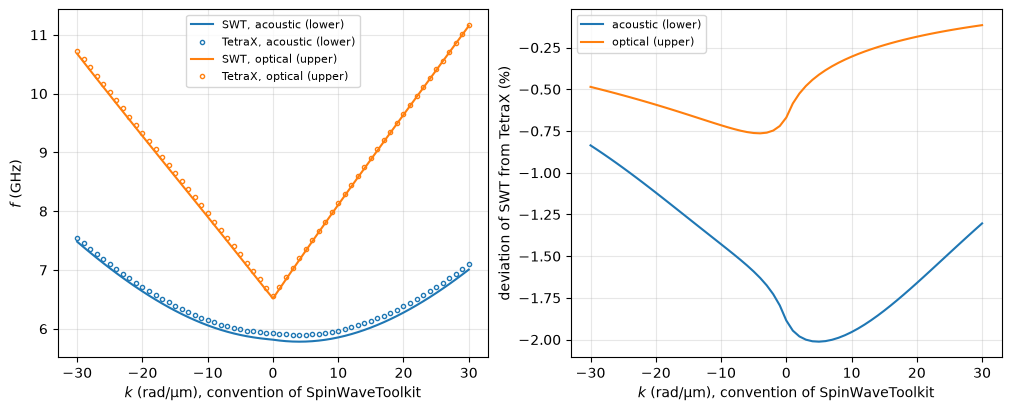

maximum deviation: acoustic 2.01 %, optical 0.76 %


In [4]:
f_tx_cmp = np.array([np.interp(-k, k_tx, f) for f in f_tx])  # TetraX at -k
dev = 100*(f_swt/f_tx_cmp - 1)  # (%) deviation of SWT from TetraX

fig, axs = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for i, name in enumerate(("acoustic (lower)", "optical (upper)")):
    axs[0].plot(k*1e-6, f_swt[i], "-", color=f"C{i}", label=f"SWT, {name}")
    axs[0].plot(-k_tx*1e-6, f_tx[i], "o", color=f"C{i}", ms=3, mfc="none",
                label=f"TetraX, {name}")
    axs[1].plot(k*1e-6, dev[i], "-", color=f"C{i}", label=name)
axs[0].set_xlabel("$k$ (rad/µm), convention of SpinWaveToolkit")
axs[0].set_ylabel("$f$ (GHz)")
axs[0].legend(fontsize=8)
axs[1].set_xlabel("$k$ (rad/µm), convention of SpinWaveToolkit")
axs[1].set_ylabel("deviation of SWT from TetraX (%)")
axs[1].legend(fontsize=8)
for ax in axs:
    ax.grid(alpha=0.3)
plt.show()
print("maximum deviation: acoustic %.2f %%, optical %.2f %%"
      % tuple(np.abs(dev).max(axis=1)))

The two calculations agree within one to two percent for both modes, including the nonreciprocity, the out-of-plane tilt of the scissors state and the different anisotropies of the two layers.  The remaining difference is the twist of the magnetization across the 5 nm layers in TetraX (the interlayer coupling acts at the interfaces only), which the macrospin layers of `DoubleLayerNumeric` cannot describe; it grows with the coupling strength and the layer thickness (e.g. with $J_{\mathrm{bl}} = -1\,\text{mJ/m}^2$ the equilibrium angles of the two codes already differ by several degrees).